# 07. Hàm Huber trên neo B

Sổ tay `W2_06_Ham_Mat_Mat_Huber` thử ba hàm mất mát nhưng chỉ trên neo A. Sổ tay notebook 04 và notebook 06 đo hiệu ứng neo nhưng chỉ với hàm MSE. Hai can thiệp này tác động lên cùng một đại lượng là chỉ số kỹ năng theo MAE, nên không được giả định cộng dồn các chỉ số.

Câu hỏi cụ thể cho việc xây dựng sổ tay này: phần lợi ích mà Huber mang lại trên neo A có còn giữ nguyên khi chuyển sang neo B hay không. Nếu còn giữ thì hai can thiệp độc lập và nên dùng cả hai. Nếu phần lợi ích teo lại thì neo B đã hấp thu sẵn tác dụng của Huber, và việc đổi hàm mất mát trở thành thứ yếu.

Thiết kế: lưới hai nhân hai gồm neo A và neo B nhân với MSE và Huber, mỗi ô ba hạt giống. Ba ô đã có sẵn ở hai lần chạy cũ nên được đọc lại thay vì chạy lại. Chỉ ô thứ tư là neo B với Huber cần huấn luyện mới. Sổ tay tự kiểm tra điều kiện ghép trước khi đọc lại, và tự huấn luyện bù nếu không tìm thấy kết quả cũ.

Đại lượng cần đọc là số hạng tương tác: hiệu của Huber trên neo B trừ hiệu của Huber trên neo A. Số hạng này được kèm khoảng tin cậy bằng lấy mẫu lặp ở cấp bệnh nhân.

> **Vị trí trong chuỗi tái lập:** notebook 07 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo, 05-Ham_mat_mat_Huber.
>
> **Thư mục kết quả:** `Output/processed/bo_sung_14_huber_neo_b/`.
>
> **Mã định danh nội bộ:** `W2_14`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "bo_sung_14_huber_neo_b"  #@param {type:"string"}
HUBER_DELTA = 1.0  #@param {type:"number"}
NGUON_HUBER = "bo_sung_06_huber"  #@param {type:"string"}
NGUON_NEO = "bo_sung_04_neo_abcd"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:17:09
run_tag      bo_sung_14_huber_neo_b
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, chỉ số và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_theo_ho_so(thu_muc, tien_to, seeds):
    ses, aes, dem = [], [], None
    for s in seeds:
        t = thu_muc / (tien_to + "_s" + str(s) + "_patient_sums.npz")
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


## 3. Tìm lại ba ô đã chạy

Ba ô của lưới đã tồn tại trong hai lần chạy trước. Ô dưới đây thiết lập để dò tên tệp theo một danh sách tiền tố có thể, vì quy ước đặt tên giữa hai đợt không giống hệt nhau. Với mỗi ô tìm được, sổ tay kiểm tra bốn điều kiện: cùng lần chạy nguồn, cùng độ dài cửa sổ, đúng neo và đúng hàm mất mát. Ô nào không đạt thì bị bỏ và sẽ được huấn luyện lại ở bước sau, nên kết quả cuối cùng luôn đầy đủ bốn ô.

In [9]:
SEEDS = list(range(N_SEEDS))

UNG_VIEN = {
    "A_mse": [(NGUON_NEO, "nlinear_neoA"), (NGUON_HUBER, "nlinear_A_mse"),
              (NGUON_HUBER, "nlinear_neoA_mse")],
    "A_huber": [(NGUON_HUBER, "nlinear_huber"), (NGUON_HUBER, "nlinear_A_huber"),
                (NGUON_HUBER, "nlinear_neoA_huber")],
    "B_mse": [(NGUON_NEO, "nlinear_neoB"), (NGUON_NEO, "nlinear_B_mse")],
    "B_huber": [],
}
MONG_DOI = {"A_mse": ("A", "mse"), "A_huber": ("A", "huber"),
            "B_mse": ("B", "mse"), "B_huber": ("B", "huber")}

NGUON_O = {}
for khoa, ds in UNG_VIEN.items():
    neo_cho, mat_mat_cho = MONG_DOI[khoa]
    for thu_muc_ten, tien_to in ds:
        thu_muc = OUT / "processed" / thu_muc_ten / "runs"
        tep = [thu_muc / (tien_to + "_s" + str(s) + ".json") for s in SEEDS]
        if not all(t.exists() for t in tep):
            continue
        ds_json = [json.loads(t.read_text()) for t in tep]
        hop_le = all(d["read_tag"] == READ_TAG and d["seq_len"] == SEQ_LEN
                     and d["pred_len"] == PRED_LEN and d["anchor"] == neo_cho
                     and d["loai_mat_mat"] == mat_mat_cho for d in ds_json)
        if not hop_le:
            print("Bỏ qua", tien_to, "vì không khớp điều kiện ghép")
            continue
        NGUON_O[khoa] = (thu_muc, tien_to, ds_json)
        print(khoa.ljust(9), "đọc lại từ", thu_muc_ten, "| tiền tố", tien_to)
        break

thieu = [k for k in MONG_DOI if k not in NGUON_O]
print("Các ô sẽ huấn luyện mới:", thieu)


A_mse     đọc lại từ bo_sung_04_neo_abcd | tiền tố nlinear_neoA
A_huber   đọc lại từ bo_sung_06_huber | tiền tố nlinear_A_huber
B_mse     đọc lại từ bo_sung_04_neo_abcd | tiền tố nlinear_neoB
Các ô sẽ huấn luyện mới: ['B_huber']


## 4. Huấn luyện các ô còn thiếu

Trong trường hợp bình thường chỉ có một ô cần huấn luyện, chi phí khoảng năm phút. Đường cơ sở Persistence cũng được chạy lại ngay tại đây, vì nó không có tham số và không tốn thời gian, lại giúp sổ tay tự chứa khi tính chỉ số kỹ năng.

In [10]:
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

for khoa in thieu:
    neo, mat_mat = MONG_DOI[khoa]
    tien_to = "nlinear_neo" + neo + "_" + mat_mat
    ds_json = []
    for s in SEEDS:
        ds_json.append(chay_mot_cau_hinh("nlinear", anchor=neo, seed=s,
                                         loai_mat_mat=mat_mat,
                                         huber_delta=HUBER_DELTA,
                                         nhan=tien_to + "_s" + str(s)))
    NGUON_O[khoa] = (RUNS, tien_to, ds_json)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neoB_huber_s0            MSE_obs 0.4342 | MAE_obs 0.4316 | 11 giây | 876 tham số
nlinear_neoB_huber_s1            MSE_obs 0.4336 | MAE_obs 0.4321 | 8 giây | 876 tham số
nlinear_neoB_huber_s2            MSE_obs 0.4339 | MAE_obs 0.4312 | 7 giây | 876 tham số
Tổng thời gian: 0.5 phút


## 5. Bảng hai nhân hai và chỉ số kỹ năng

Hai chỉ số được báo cáo song song. Sai số bình phương cho biết độ chính xác ở phần đuôi phân bố, sai số tuyệt đối cho biết độ chính xác ở phần thân. Chỉ số kỹ năng theo MAE là đại lượng mà cả hai can thiệp cùng nhắm tới, nên nó là cột đọc chính.

In [11]:
tong_hop = {}
for khoa in ("A_mse", "A_huber", "B_mse", "B_huber"):
    _, _, ds_json = NGUON_O[khoa]
    mse = np.array([d["test"]["mse"] for d in ds_json])
    mae = np.array([d["test"]["mae"] for d in ds_json])
    tong_hop[khoa] = {
        "neo": MONG_DOI[khoa][0],
        "ham_mat_mat": MONG_DOI[khoa][1],
        "so_hat_giong": int(len(mse)),
        "mse_trung_binh": float(mse.mean()),
        "mse_do_lech_chuan": float(mse.std(ddof=1)) if len(mse) > 1 else 0.0,
        "mae_trung_binh": float(mae.mean()),
        "ky_nang_mae": float(1.0 - mae.mean() / MAE_PERSISTENCE),
        "cac_gia_tri_mse": [float(v) for v in mse],
    }
    print(khoa.ljust(9), "MSE", round(float(mse.mean()), 6),
          "| MAE", round(float(mae.mean()), 6),
          "| chỉ số kỹ năng MAE", round(tong_hop[khoa]["ky_nang_mae"], 6))
print("Persistence | MSE", round(MSE_PERSISTENCE, 6), "| MAE",
      round(MAE_PERSISTENCE, 6))


A_mse     MSE 0.488031 | MAE 0.471698 | chỉ số kỹ năng MAE -0.012351
A_huber   MSE 0.486836 | MAE 0.467474 | chỉ số kỹ năng MAE -0.003286
B_mse     MSE 0.436036 | MAE 0.437276 | chỉ số kỹ năng MAE 0.061526
B_huber   MSE 0.433919 | MAE 0.431624 | chỉ số kỹ năng MAE 0.073655
Persistence | MSE 0.578754 | MAE 0.465943


In [12]:
# Hai hiệu ứng riêng và một số hạng tương tác, tính trên chỉ số kỹ năng MAE.
hieu_ung = {
    "huber_tren_neoA": tong_hop["A_huber"]["ky_nang_mae"] - tong_hop["A_mse"]["ky_nang_mae"],
    "huber_tren_neoB": tong_hop["B_huber"]["ky_nang_mae"] - tong_hop["B_mse"]["ky_nang_mae"],
    "neo_voi_mse": tong_hop["B_mse"]["ky_nang_mae"] - tong_hop["A_mse"]["ky_nang_mae"],
    "neo_voi_huber": tong_hop["B_huber"]["ky_nang_mae"] - tong_hop["A_huber"]["ky_nang_mae"],
}
hieu_ung = {k: float(v) for k, v in hieu_ung.items()}
hieu_ung["tuong_tac_ky_nang_mae"] = float(hieu_ung["huber_tren_neoB"] -
                                          hieu_ung["huber_tren_neoA"])
cong_don = float(tong_hop["A_mse"]["ky_nang_mae"] + hieu_ung["huber_tren_neoA"] +
                 hieu_ung["neo_voi_mse"])
hieu_ung["du_doan_cong_don"] = cong_don
hieu_ung["thuc_te_ca_hai"] = float(tong_hop["B_huber"]["ky_nang_mae"])
for k, v in hieu_ung.items():
    print(k.ljust(26), round(v, 6))


huber_tren_neoA            0.009065
huber_tren_neoB            0.012129
neo_voi_mse                0.073877
neo_voi_huber              0.076941
tuong_tac_ky_nang_mae      0.003064
du_doan_cong_don           0.070591
thuc_te_ca_hai             0.073655


## 6. Kiểm định bắt cặp cho số hạng tương tác

Số hạng tương tác là một hiệu của hai hiệu, nên sai số chuẩn của nó lớn hơn sai số chuẩn của từng hiệu. Không được kết luận từ bốn con số trung bình mà không có khoảng tin cậy. Bốn ô dùng chung một tập kiểm tra, nên phép lấy mẫu lặp ở cấp bệnh nhân dùng chung một danh sách chỉ số cho cả bốn, nhờ vậy phần biến thiên chung bị triệt tiêu.

In [13]:
TONG = {}
dem_chuan = None
for khoa in ("A_mse", "A_huber", "B_mse", "B_huber"):
    thu_muc, tien_to, _ = NGUON_O[khoa]
    se, ae, dem = nap_tong_theo_ho_so(thu_muc, tien_to, SEEDS)
    if dem_chuan is None:
        dem_chuan = dem
    assert len(dem) == len(dem_chuan), "Số hồ sơ kiểm tra không khớp giữa các ô"
    assert np.allclose(dem, dem_chuan), "Số điểm đo không khớp, tập kiểm tra khác nhau"
    TONG[khoa] = (se, ae)
print("Bốn ô dùng chung tập kiểm tra", len(dem_chuan), "hồ sơ")


Bốn ô dùng chung tập kiểm tra 1585 hồ sơ


In [14]:
def tuong_tac_bat_cap(tong, dem, n_boot=5000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho số hạng tương tác của lưới hai nhân hai."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = ((tong["B_huber"][0][idx].sum() - tong["B_mse"][0][idx].sum()) -
                    (tong["A_huber"][0][idx].sum() - tong["A_mse"][0][idx].sum())) / mau
        d_mae[b] = ((tong["B_huber"][1][idx].sum() - tong["B_mse"][1][idx].sum()) -
                    (tong["A_huber"][1][idx].sum() - tong["A_mse"][1][idx].sum())) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    tt_mse = ((tong["B_huber"][0].sum() - tong["B_mse"][0].sum()) -
              (tong["A_huber"][0].sum() - tong["A_mse"][0].sum())) / mau_that
    tt_mae = ((tong["B_huber"][1].sum() - tong["B_mse"][1].sum()) -
              (tong["A_huber"][1].sum() - tong["A_mse"][1].sum())) / mau_that
    return {
        "tuong_tac_mse": float(tt_mse),
        "tuong_tac_mse_ci": [float(np.percentile(d_mse, lo)),
                             float(np.percentile(d_mse, hi))],
        "tuong_tac_mae": float(tt_mae),
        "tuong_tac_mae_ci": [float(np.percentile(d_mae, lo)),
                             float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mae": d_mae,
    }


tt = tuong_tac_bat_cap(TONG, dem_chuan, n_boot=N_BOOT, seed=0)
print("Tương tác theo MAE", round(tt["tuong_tac_mae"], 6),
      "| khoảng tin cậy", [round(v, 6) for v in tt["tuong_tac_mae_ci"]],
      "| p", round(tt["p_hai_phia_mae"], 4))
print("Tương tác theo MSE", round(tt["tuong_tac_mse"], 6),
      "| khoảng tin cậy", [round(v, 6) for v in tt["tuong_tac_mse_ci"]],
      "| p", round(tt["p_hai_phia_mse"], 4))


Tương tác theo MAE -0.001428 | khoảng tin cậy [-0.001812, -0.001065] | p 0.0
Tương tác theo MSE -0.000922 | khoảng tin cậy [-0.002093, 0.000316] | p 0.1308


In [15]:
# Ba phép so sánh đơn theo cặp, để đặt số hạng tương tác vào đúng bối cảnh.
bat_cap = {}
for ten, a, b in (("huber_tru_mse_tren_neoA", "A_huber", "A_mse"),
                  ("huber_tru_mse_tren_neoB", "B_huber", "B_mse"),
                  ("neoB_tru_neoA_voi_huber", "B_huber", "A_huber")):
    r = hieu_so_bat_cap(TONG[a][0], TONG[a][1], TONG[b][0], TONG[b][1],
                        dem_chuan, n_boot=N_BOOT, seed=0)
    bat_cap[ten] = {k: v for k, v in r.items() if not k.startswith("mau_bootstrap")}
    print(ten.ljust(26), "hiệu MSE", round(r["hieu_mse"], 6),
          "| hiệu MAE", round(r["hieu_mae"], 6),
          "| p theo MAE", round(r["p_hai_phia_mae"], 4))


huber_tru_mse_tren_neoA    hiệu MSE -0.001195 | hiệu MAE -0.004224 | p theo MAE 0.0
huber_tru_mse_tren_neoB    hiệu MSE -0.002118 | hiệu MAE -0.005652 | p theo MAE 0.0
neoB_tru_neoA_voi_huber    hiệu MSE -0.052918 | hiệu MAE -0.03585 | p theo MAE 0.0


## 7. Hình và tệp kết quả

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b/figures/fig29_huber_va_neo_b.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b/figures/fig29_huber_va_neo_b.png')

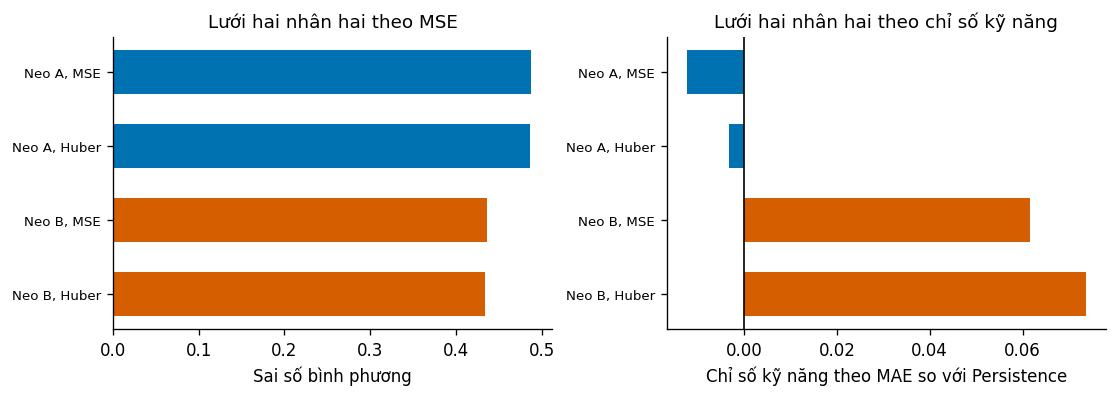

In [16]:
khoa4 = ["A_mse", "A_huber", "B_mse", "B_huber"]
nhan4 = ["Neo A, MSE", "Neo A, Huber", "Neo B, MSE", "Neo B, Huber"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
axes[0].barh(np.arange(4), [tong_hop[k]["mse_trung_binh"] for k in khoa4],
             color=[PALETTE[0], PALETTE[0], PALETTE[1], PALETTE[1]], height=0.6)
axes[0].set_yticks(np.arange(4))
axes[0].set_yticklabels(nhan4, fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlabel("Sai số bình phương")
axes[0].set_title("Lưới hai nhân hai theo MSE")
axes[1].barh(np.arange(4), [tong_hop[k]["ky_nang_mae"] for k in khoa4],
             color=[PALETTE[0], PALETTE[0], PALETTE[1], PALETTE[1]], height=0.6)
axes[1].axvline(0.0, color="black", linewidth=1.0)
axes[1].set_yticks(np.arange(4))
axes[1].set_yticklabels(nhan4, fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xlabel("Chỉ số kỹ năng theo MAE so với Persistence")
axes[1].set_title("Lưới hai nhân hai theo chỉ số kỹ năng")
luu_hinh(fig, "fig29_huber_va_neo_b.png")


Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b/figures/fig30_tuong_tac_huber_neo.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b/figures/fig30_tuong_tac_huber_neo.png')

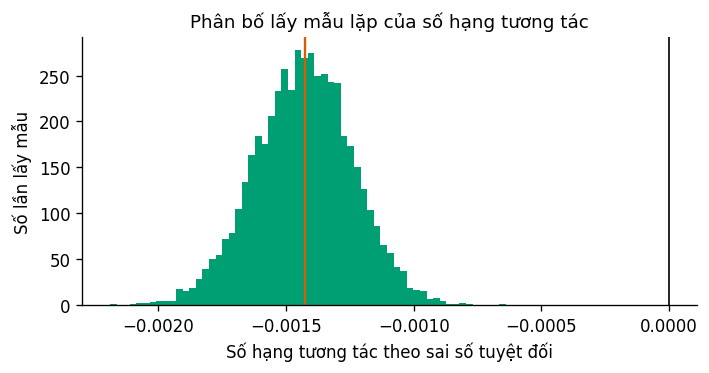

In [17]:
fig, ax = plt.subplots(figsize=(5.8, 3.0))
ax.hist(tt["mau_bootstrap_mae"], bins=60, color=PALETTE[2])
ax.axvline(0.0, color="black", linewidth=1.0)
ax.axvline(tt["tuong_tac_mae"], color=PALETTE[1], linewidth=1.4)
ax.set_xlabel("Số hạng tương tác theo sai số tuyệt đối")
ax.set_ylabel("Số lần lấy mẫu")
ax.set_title("Phân bố lấy mẫu lặp của số hạng tương tác")
luu_hinh(fig, "fig30_tuong_tac_huber_neo.png")


In [18]:
bao_cao = {"kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
           "read_tag": READ_TAG, "run_tag": RUN_TAG, "n_seeds": N_SEEDS,
           "huber_delta": HUBER_DELTA, "n_boot": N_BOOT,
           "nguon_tung_o": {k: str(v[0]) + "|" + v[1] for k, v in NGUON_O.items()},
           "o_huan_luyen_moi": thieu,
           "mse_persistence": MSE_PERSISTENCE,
           "mae_persistence": MAE_PERSISTENCE,
           "tong_hop": tong_hop, "hieu_ung": hieu_ung,
           "tuong_tac": {k: v for k, v in tt.items()
                         if not k.startswith("mau_bootstrap")},
           "bat_cap_theo_benh_nhan": bat_cap, "env": ENV}
(RUN_DIR / "W2_huber_neo_b.json").write_text(
    json.dumps(bao_cao, ensure_ascii=False, indent=2))
print("Đã ghi", RUN_DIR / "W2_huber_neo_b.json")


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_14_huber_neo_b/W2_huber_neo_b.json


## 8. Cách đọc kết quả

- Dòng cần xem trước là `tuong_tac_mae` cùng khoảng tin cậy của nó. Nếu khoảng tin cậy chứa mốc không thì hai can thiệp cộng dồn, và có thể dùng cả hai trong các thực nghiệm kế tiếp.
- Nếu số hạng tương tác dương và có ý nghĩa thì phần lợi ích của Huber bị neo B hấp thu, tức hai can thiệp cha lấn nhau. Khi đó nên giữ neo B làm can thiệp chính và báo cáo Huber như một biến thể.
- `du_doan_cong_don` so với `thuc_te_ca_hai` là cách đọc trực quan của cùng một điều. Hai con số càng gần nhau thì mô hình cộng dồn càng đúng.
- Cột `mse_trung_binh` vẫn phải được kiểm tra song song. Một can thiệp làm tốt chỉ số này mà làm xấu chỉ số kia thì phải báo cáo như một đánh đổi, không phải một cải tiến.
- `o_huan_luyen_moi` ghép bằng rỗng hoặc chỉ chứa `B_huber` là dấu hiệu việc đọc lại kết quả cũ đã hoạt động đúng. Nếu danh sách dài hơn thì các sổ tay đợt trước chưa được chạy, sổ tay này vẫn cho kết quả đầy đủ nhưng tốn thêm thời gian.